### 💡 데이터 분포의 형태 분석


평균: 54857.142857142855
중앙값: 26000.0


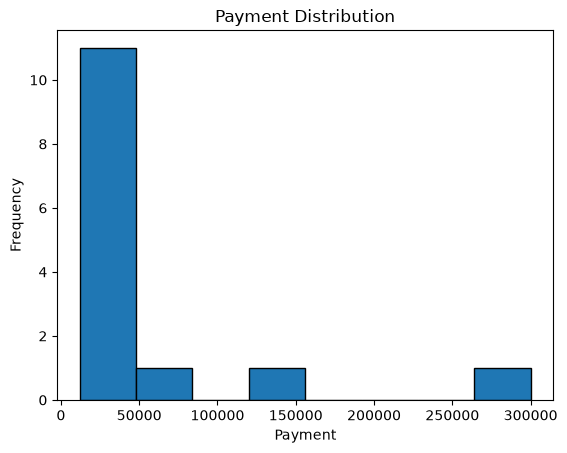

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

payments = pd.Series([
    12000, 15000, 18000, 20000, 22000,
    24000, 25000, 27000, 30000, 35000,
    40000, 50000, 150000, 300000
])

print("평균:", payments.mean())
print("중앙값:", payments.median())

plt.hist(payments, bins=8, edgecolor="black")
plt.title("Payment Distribution")
plt.xlabel("Payment")
plt.ylabel("Frequency")
plt.show()

여기서 생각 할 수 있는 것은 아래와 같다.
- 소수의 고액 결제 고객이 평균을 크게 올리고 있는가
- 높은 결제 금액은 오류인가, 실제 VIP 고객인가
- 전체 고객의 대표 결제 금액으로 평균이 적절한가
- 고액 결제 고객을 별도로 분석해야 하는가

이처럼 분포를 확인한다는 것은 그래프를 그리는 것 뿐만 아니라, 데이터의 특성을 파악하고 다음 분석 방향을 결정하는 것이다.

#### 왜도 (Skewness)
왜도는 데이터 분포의 비대칭 정보를 나타내는 통계량이다. 

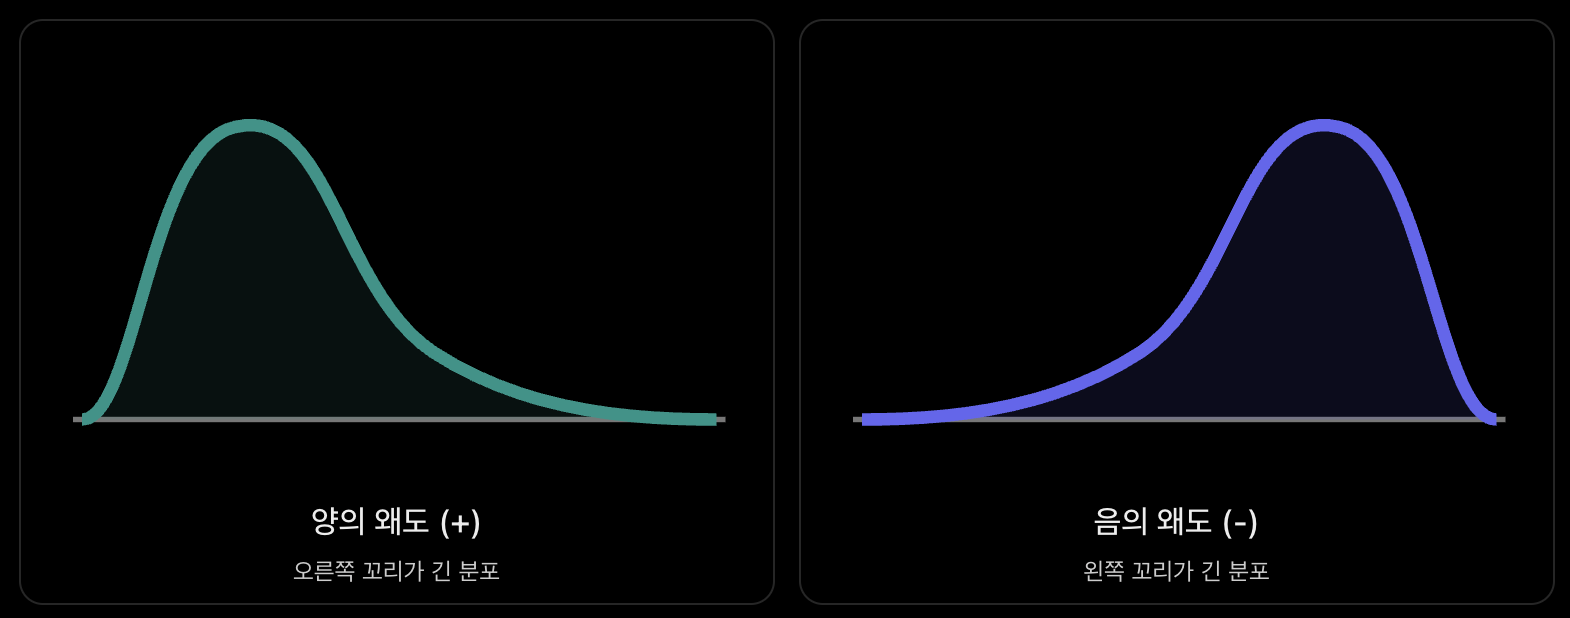

In [ ]:
# 왜도 계산
# 양수가 나오면 오른쪽으로 긴 꼬리가 있는 경향
# 음수가 나오면 왼쪽으로 긴 꼬리가 있는 경햐
# 그렇지만 왜도 수치 하나만으로 분포를 단정하지 말고 히스토그램, 이상치, 표본 크기도 함께 확인해야 한다.

print("왜도 :", payments.skew())

왜도 : 2.8238496039481444


#### 첨도 (Kurtosis)

첨도는 분포에서 극단적인 값이 나타나는 경향과 관련된 지표이다.

꼬리와 극단값에 대한 민감도를 이해하는 것이 유용하다.

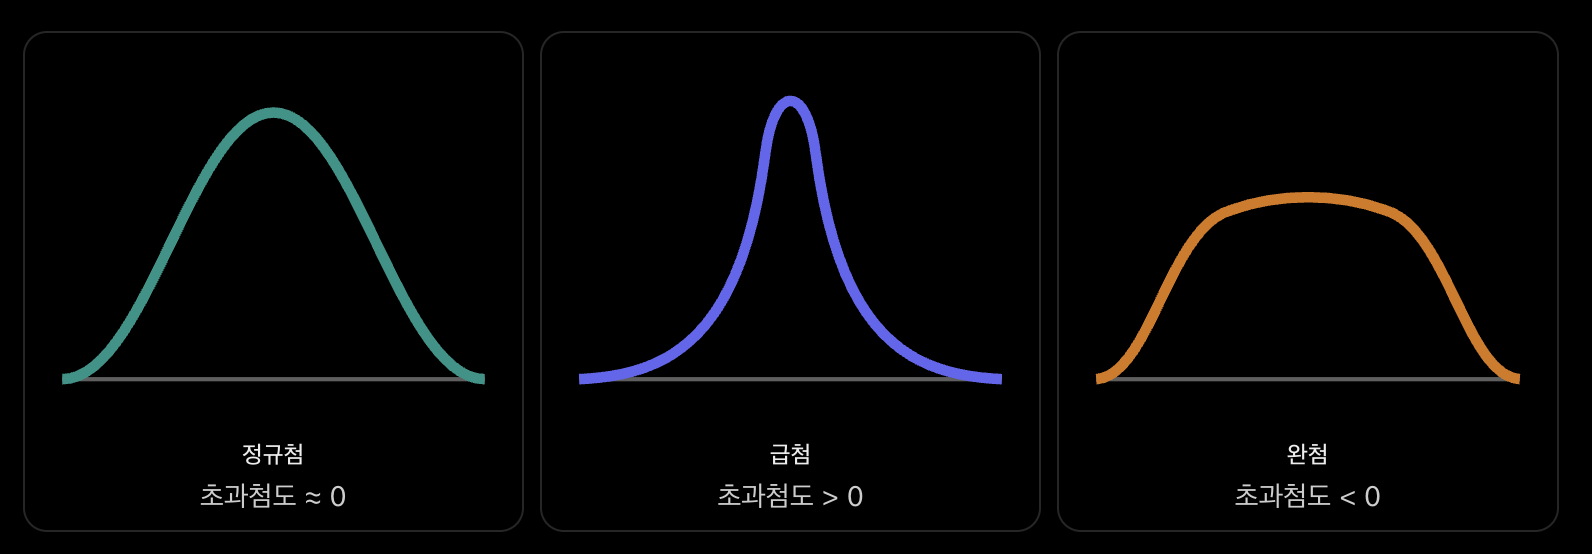

In [5]:
print("첨도 :", payments.kurt())

첨도 : 8.106783664357877


      mean  median    std  skew  kurtosis  missing
age   29.7   28.00  14.53  0.39      0.18      177
fare  32.2   14.45  49.69  4.79     33.40        0


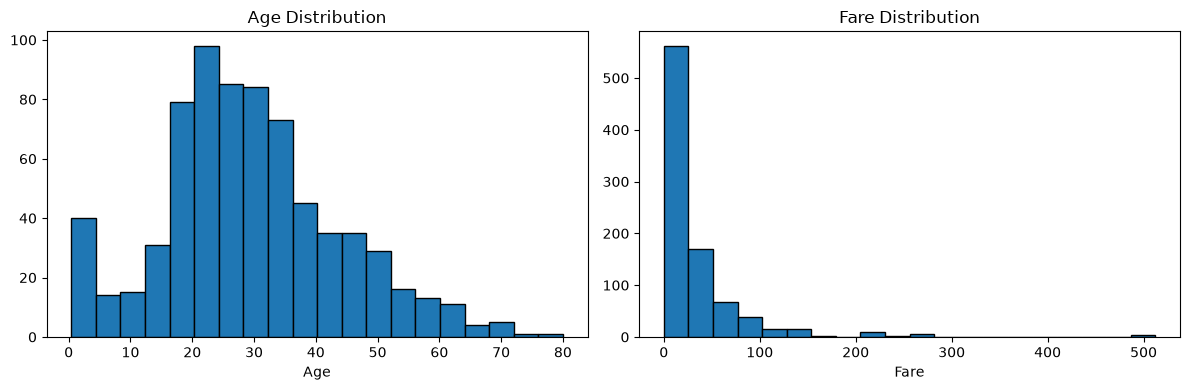

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("./datasets/titanic.csv")

columns = ["age", "fare"]

summary = pd.DataFrame({
    "mean": df[columns].mean(),
    "median": df[columns].median(),
    "std": df[columns].std(),
    "skew": df[columns].skew(),
    "kurtosis": df[columns].kurt(),
    "missing": df[columns].isna().sum()
})

print(summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["age"].dropna(), bins=20, edgecolor="black")
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")

axes[1].hist(df["fare"].dropna(), bins=20, edgecolor="black")
axes[1].set_title("Fare Distribution")
axes[1].set_xlabel("Fare")

plt.tight_layout()
plt.show()